# Evaluación por máquina y por modelo

Matrices de confusión, predicciones, duración de colas (bloques seguidos) y tendencias de cuándo y por qué ocurren.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)

from setup import common_test_rows, load_test_data, prepare_models

BLOCK_HOURS = 0.5            # cada bloque = 30 min
MAX_ROWS_PRINT = 20          # filas que se imprimen por máquina-modelo (CSV completo se guarda)
DRIVER_COLUMNS = [           # variables para explicar "por qué" arranca una cola
    "total_ordenios", "pct_ocupacion_robot", "duracion_total_min",
    "patadas_totales", "desviaciones_leche_totales", "ordenios_con_lavado",
    "hubo_lavado", "ordenios_otros_robots", "vacas_activas_dia",
]

data = load_test_data()
models, predictions = prepare_models(data)
common_rows = common_test_rows(data, predictions)
print(f"Filas de test compartidas: {len(common_rows):,} de {len(data.test):,}")

# Umbral de decisión por modelo (GRU y logística traen el suyo; el resto 0.5, editable).
THRESHOLDS = {name: 0.5 for name in predictions}
THRESHOLDS["GRU"] = data.gru_decision_threshold
THRESHOLDS["Regresión logística"] = data.logistic_decision_threshold
print("Umbrales:", THRESHOLDS)

Datos: 179,850 filas; train=125,894, validación=26,978, test=26,978
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['gru_E2_w48.keras', 'gru_E2_w48_scaler.joblib', 'logistic_regresion.keras', 'lstm_model.keras', 'mlp_classifier.joblib', 'tcn_classification_base_w48.keras']


c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to

Variables de entrada: {'Regresión logística': 25, 'LSTM': (24, 29), 'GRU/TCN': (48, 27), 'MLPClassifier': 41}
Filas de test con predicción por modelo: {'GRU': 26978, 'TCN': 26978, 'LSTM': 26978, 'Regresión logística': 26978, 'MLPClassifier': 26978}
Filas de test compartidas: 26,978 de 26,978
Umbrales: {'GRU': 0.35, 'TCN': 0.5, 'LSTM': 0.5, 'Regresión logística': 0.2095, 'MLPClassifier': 0.5}


## Base común (real)

In [2]:
driver_cols = [c for c in DRIVER_COLUMNS if c in data.full_data.columns]
base_cols = ["bloque_tiempo", "ms", "hora", "dia_semana", "temporada", data.target] + driver_cols
base = data.full_data.set_index("__row_id__").loc[common_rows, base_cols].copy()
base["bloque_tiempo"] = pd.to_datetime(base["bloque_tiempo"])
base["y_true"] = (base[data.target] > data.label_threshold).astype(int)
base = base.sort_values(["ms", "bloque_tiempo"])
machines = sorted(base["ms"].dropna().unique())
model_names = list(predictions)

frames = {}  # (modelo) -> DataFrame con score y y_pred
for name in model_names:
    df = base.copy()
    df["score"] = predictions[name].reindex(df.index).to_numpy(dtype=float)
    df["y_pred"] = (df["score"] >= THRESHOLDS[name]).astype(int)
    frames[name] = df

## 1) Métricas + matrices de confusión por máquina-modelo

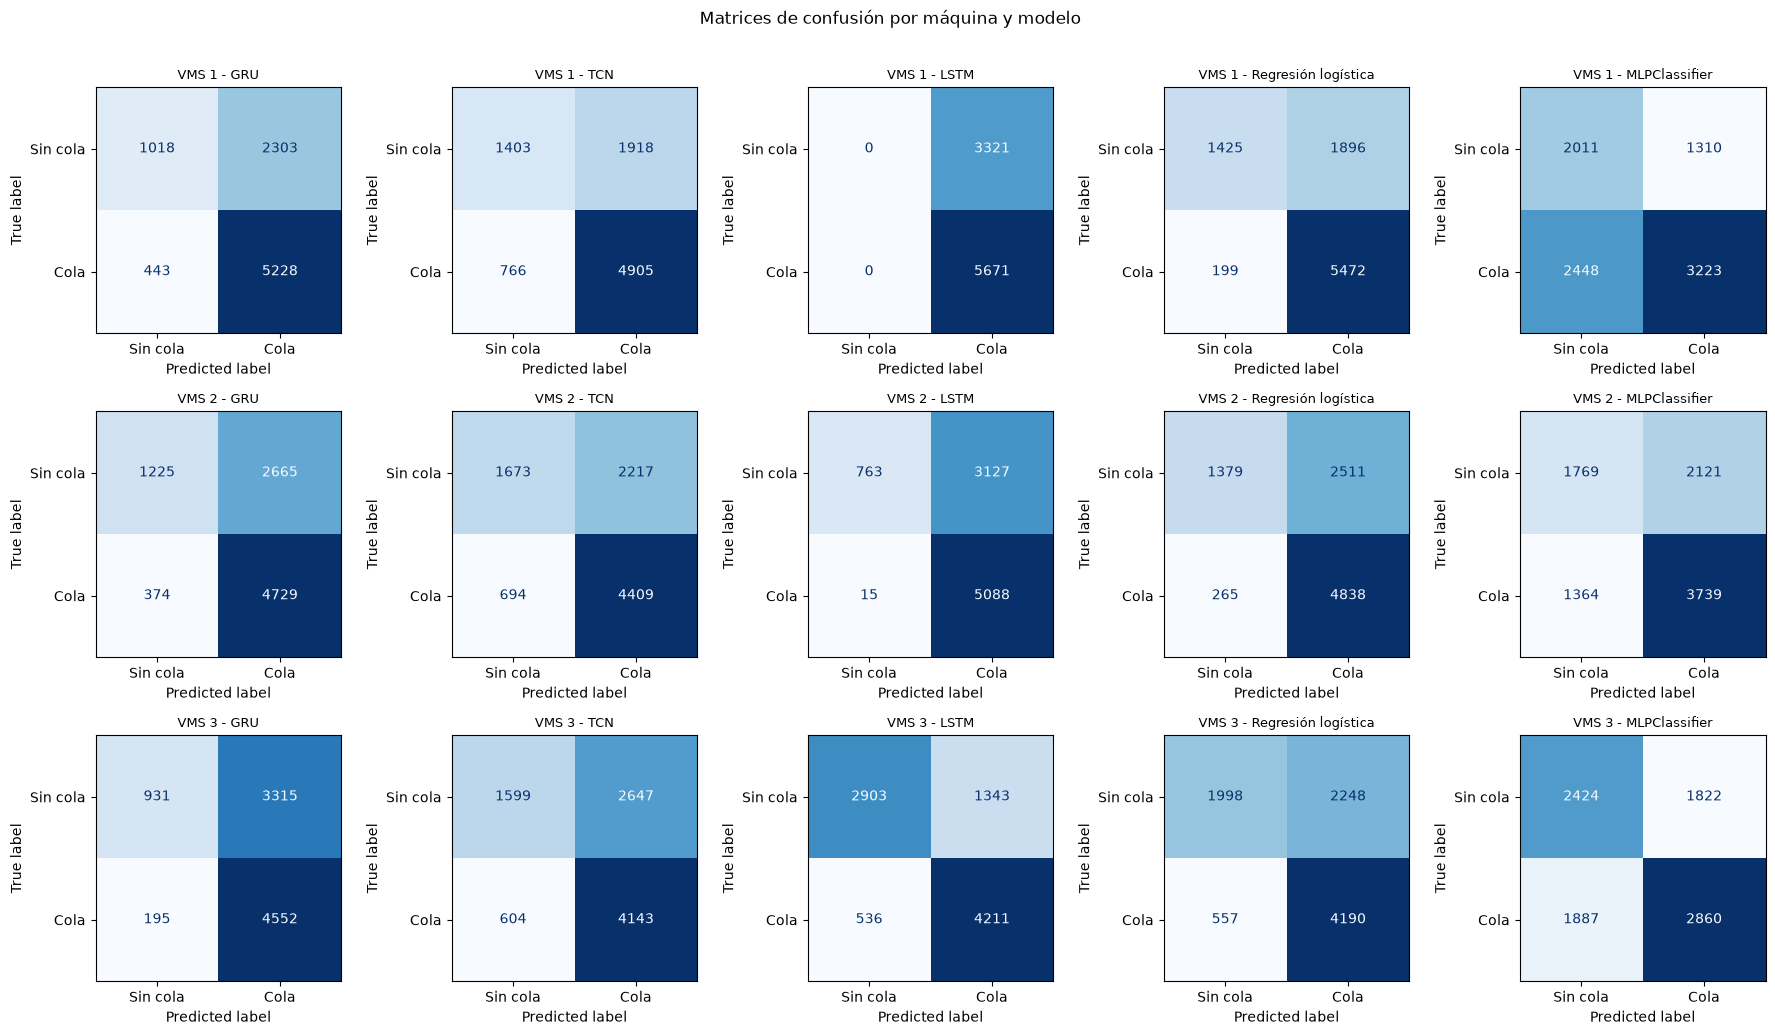

   ms              modelo    n  cola_real_%  cola_pred_%   TN   FP   FN   TP  accuracy  precision  recall    f1
VMS 1                 GRU 8992       63.067       83.752 1018 2303  443 5228     0.695      0.694   0.922 0.792
VMS 1                 TCN 8992       63.067       75.879 1403 1918  766 4905     0.702      0.719   0.865 0.785
VMS 1                LSTM 8992       63.067      100.000    0 3321    0 5671     0.631      0.631   1.000 0.774
VMS 1 Regresión logística 8992       63.067       81.940 1425 1896  199 5472     0.767      0.743   0.965 0.839
VMS 1       MLPClassifier 8992       63.067       50.411 2011 1310 2448 3223     0.582      0.711   0.568 0.632
VMS 2                 GRU 8993       56.744       82.220 1225 2665  374 4729     0.662      0.640   0.927 0.757
VMS 2                 TCN 8993       56.744       73.680 1673 2217  694 4409     0.676      0.665   0.864 0.752
VMS 2                LSTM 8993       56.744       91.349  763 3127   15 5088     0.651      0.619   0.99

In [9]:
metric_rows = []
fig, axes = plt.subplots(
    len(machines), len(model_names),
    figsize=(3.6 * len(model_names), 3.4 * len(machines)), squeeze=False,
)
for i, machine in enumerate(machines):
    for j, name in enumerate(model_names):
        g = frames[name].loc[frames[name]["ms"] == machine]
        cm = confusion_matrix(g["y_true"], g["y_pred"], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Sin cola", "Cola"]).plot(
            ax=axes[i, j], colorbar=False, values_format="d", cmap="Blues"
        )
        axes[i, j].set_title(f"{machine} - {name}", fontsize=9)
        tn, fp, fn, tp = cm.ravel()
        metric_rows.append({
            "ms": machine, "modelo": name, "n": len(g),
            "cola_real_%": 100 * g["y_true"].mean(),
            "cola_pred_%": 100 * g["y_pred"].mean(),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": accuracy_score(g["y_true"], g["y_pred"]),
            "precision": precision_score(g["y_true"], g["y_pred"], zero_division=0),
            "recall": recall_score(g["y_true"], g["y_pred"], zero_division=0),
            "f1": f1_score(g["y_true"], g["y_pred"], zero_division=0),
        })
fig.suptitle("Matrices de confusión por máquina y modelo", y=1.01)
fig.tight_layout()
plt.show()

metrics = pd.DataFrame(metric_rows)
print(metrics.round(3).to_string(index=False))

## 2) Predicciones por máquina-modelo

In [8]:
# out_dir = data.project_root / "reports"
# out_dir.mkdir(exist_ok=True)
# for name in model_names:
#     for machine in machines:
#         g = frames[name].loc[frames[name]["ms"] == machine, [
#             "bloque_tiempo", data.target, "y_true", "score", "y_pred"
#         ]]
#         safe = f"{machine}_{name}".replace(" ", "_")
#         g.to_csv(out_dir / f"predicciones_{safe}.csv")
#         print(f"\n=== {machine} | {name} (umbral={THRESHOLDS[name]:.3f}) | {len(g):,} filas ===")
#         print(g.head(MAX_ROWS_PRINT).round(3).to_string())
# print(f"\nCSV completos en: {out_dir}")

## 3) Episodios de cola (bloques consecutivos)

   ms              modelo  episodios_real  episodios_pred  dur_media_real_h  dur_media_pred_h  dur_mediana_real_h  dur_mediana_pred_h  dur_max_real_h  dur_max_pred_h  colas_detectadas_%  retraso_inicio_med_h  desfase_fin_med_h  falsas_alarmas_%
VMS 1                 GRU            1653             622              1.72              6.05                 1.0                 6.5            10.0            23.5               91.83                   0.0                2.5              8.36
VMS 2                 GRU            1672             658              1.53              5.62                 1.0                 6.0             8.0            23.5               93.42                   0.0                2.5              9.57
VMS 3                 GRU            1839             575              1.29              6.84                 1.0                 6.5             7.5            23.5               95.87                   0.0                3.5             11.13
VMS 1               

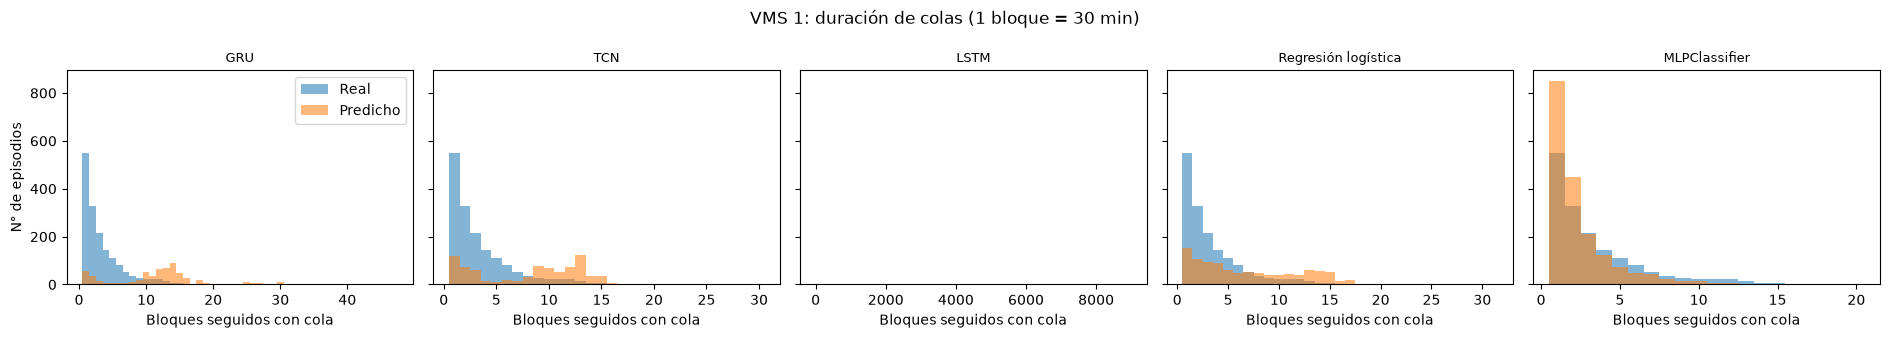

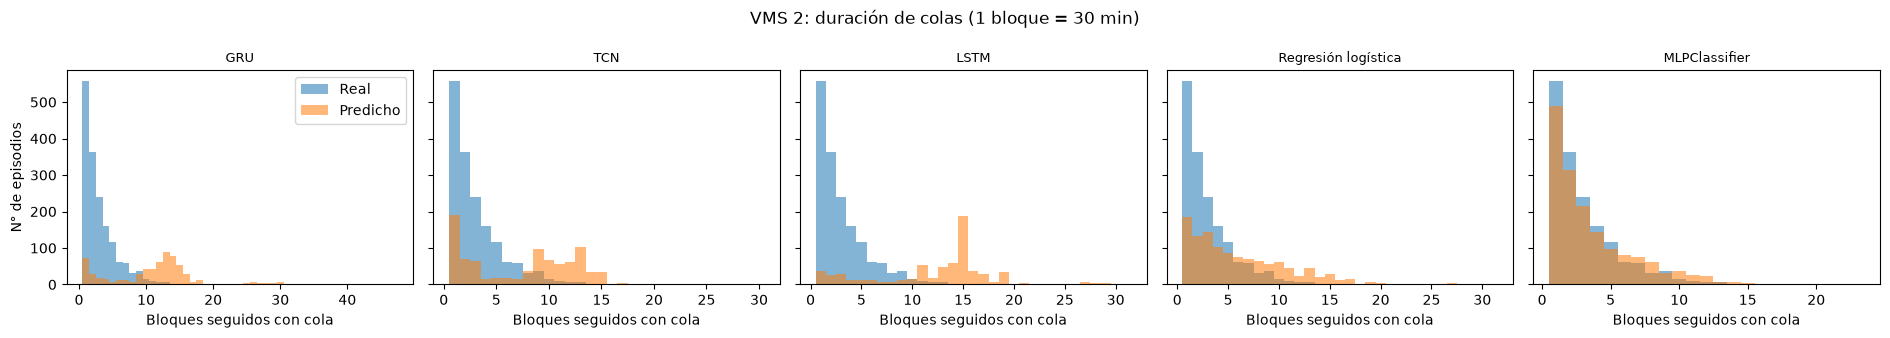

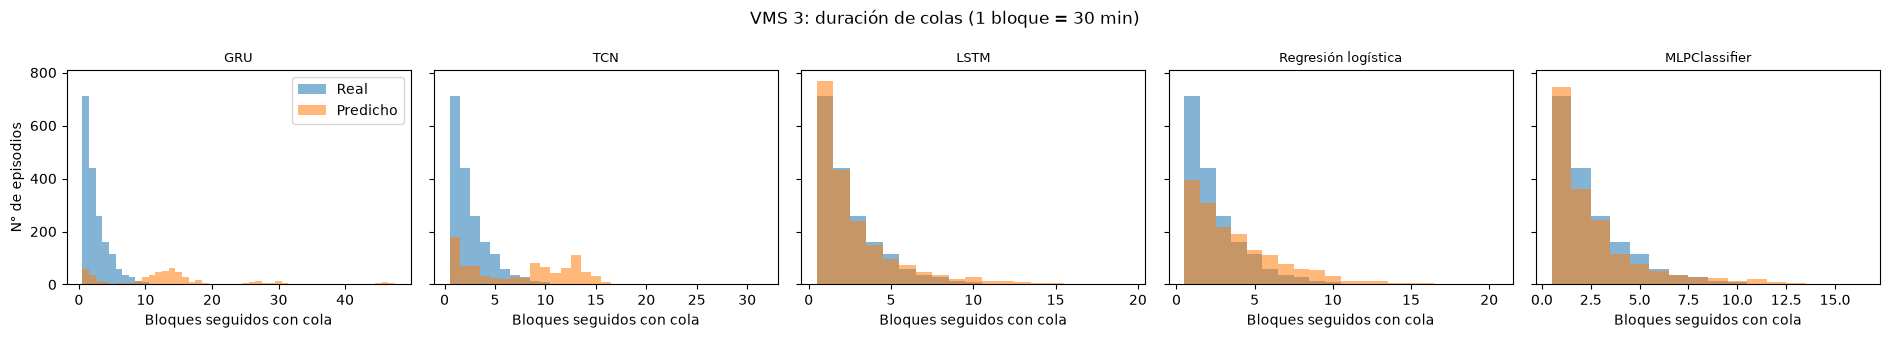

In [5]:
def find_episodes(values, times):
    """Posiciones (inicio, fin) de rachas de 1 en bloques contiguos de 30 min."""
    if len(values) == 0:
        return np.array([], int), np.array([], int)
    gap = np.r_[False, np.diff(times) != np.timedelta64(30, "m")]
    change = np.r_[True, values[1:] != values[:-1]] | gap
    starts = np.flatnonzero(change)
    ends = np.r_[starts[1:] - 1, len(values) - 1]
    keep = values[starts] == 1
    return starts[keep], ends[keep]


def machine_episode_report(g):
    """Compara episodios reales vs predichos de una máquina (g ya ordenado por tiempo)."""
    y_t, y_p = g["y_true"].to_numpy(), g["y_pred"].to_numpy()
    t = g["bloque_tiempo"].to_numpy(dtype="datetime64[ns]")
    rs, re_ = find_episodes(y_t, t)
    ps, pe = find_episodes(y_p, t)

    real_eps = []
    for s, e in zip(rs, re_):
        hits = np.flatnonzero(y_p[s:e + 1])
        row = {"inicio": t[s], "bloques_real": e - s + 1, "detectada": len(hits) > 0}
        if len(hits):
            first, last = s + hits[0], s + hits[-1]
            k_last = np.searchsorted(ps, last, side="right") - 1
            row.update({
                "retraso_inicio_bloques": hits[0],         # >0: el modelo avisa tarde
                "bloques_pred_dentro": len(hits),
                "fin_pred_menos_fin_real": pe[k_last] - e,  # >0: la predicción tarda en "bajar"
            })
        real_eps.append(row)

    cum = np.r_[0, np.cumsum(y_t)]
    false_alarm = [(cum[e + 1] - cum[s]) == 0 for s, e in zip(ps, pe)]
    pred_eps = pd.DataFrame({
        "inicio": t[ps] if len(ps) else [], "bloques_pred": pe - ps + 1,
        "falsa_alarma": false_alarm,
    })
    return (
        pd.DataFrame(real_eps), pred_eps,
        pd.DataFrame({"bloques": re_ - rs + 1}), pd.DataFrame({"bloques": pe - ps + 1}),
    )


summary_rows, episode_store = [], {}
for name in model_names:
    for machine in machines:
        g = frames[name].loc[frames[name]["ms"] == machine].sort_values("bloque_tiempo")
        real_df, pred_df, real_len, pred_len = machine_episode_report(g)
        episode_store[(machine, name)] = (real_df, pred_df, real_len, pred_len)

        det = real_df["detectada"] if len(real_df) else pd.Series(dtype=bool)
        summary_rows.append({
            "ms": machine, "modelo": name,
            "episodios_real": len(real_len), "episodios_pred": len(pred_len),
            "dur_media_real_h": real_len["bloques"].mean() * BLOCK_HOURS,
            "dur_media_pred_h": pred_len["bloques"].mean() * BLOCK_HOURS,
            "dur_mediana_real_h": real_len["bloques"].median() * BLOCK_HOURS,
            "dur_mediana_pred_h": pred_len["bloques"].median() * BLOCK_HOURS,
            "dur_max_real_h": real_len["bloques"].max() * BLOCK_HOURS,
            "dur_max_pred_h": pred_len["bloques"].max() * BLOCK_HOURS,
            "colas_detectadas_%": 100 * det.mean() if len(det) else np.nan,
            "retraso_inicio_med_h": (
                real_df.get("retraso_inicio_bloques", pd.Series(dtype=float)).median() * BLOCK_HOURS
            ),
            "desfase_fin_med_h": (
                real_df.get("fin_pred_menos_fin_real", pd.Series(dtype=float)).median() * BLOCK_HOURS
            ),
            "falsas_alarmas_%": 100 * pred_df["falsa_alarma"].mean() if len(pred_df) else np.nan,
        })

episode_summary = pd.DataFrame(summary_rows)
print(episode_summary.round(2).to_string(index=False))
episode_summary.to_csv(out_dir / "resumen_episodios.csv", index=False)

# Histogramas de duración de episodios: real vs predicho (una figura por máquina)
for machine in machines:
    fig, axes = plt.subplots(1, len(model_names), figsize=(3.8 * len(model_names), 3.4),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes[0], model_names):
        _, _, real_len, pred_len = episode_store[(machine, name)]
        top = max(real_len["bloques"].max() if len(real_len) else 1,
                  pred_len["bloques"].max() if len(pred_len) else 1)
        bins = np.arange(1, top + 2) - 0.5
        ax.hist(real_len["bloques"], bins=bins, alpha=0.55, label="Real")
        ax.hist(pred_len["bloques"], bins=bins, alpha=0.55, label="Predicho")
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("Bloques seguidos con cola")
    axes[0, 0].set_ylabel("N° de episodios")
    axes[0, 0].legend()
    fig.suptitle(f"{machine}: duración de colas (1 bloque = 30 min)")
    fig.tight_layout()
    plt.show()

## 4) Tendencias: cuándo ocurren (hora, día de semana, temporada)

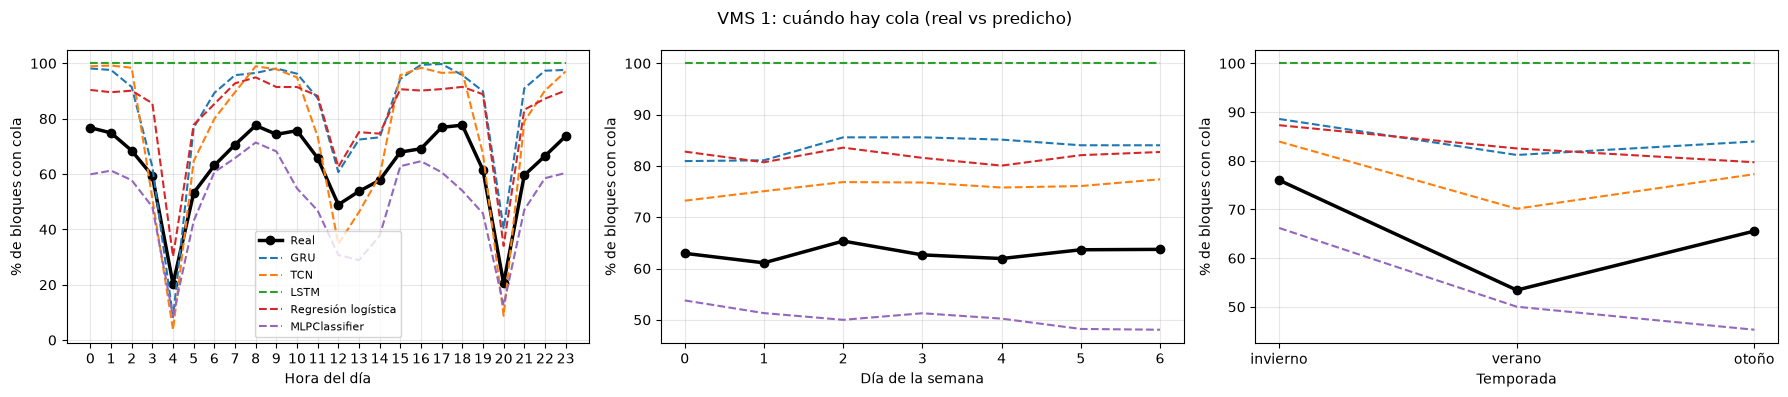

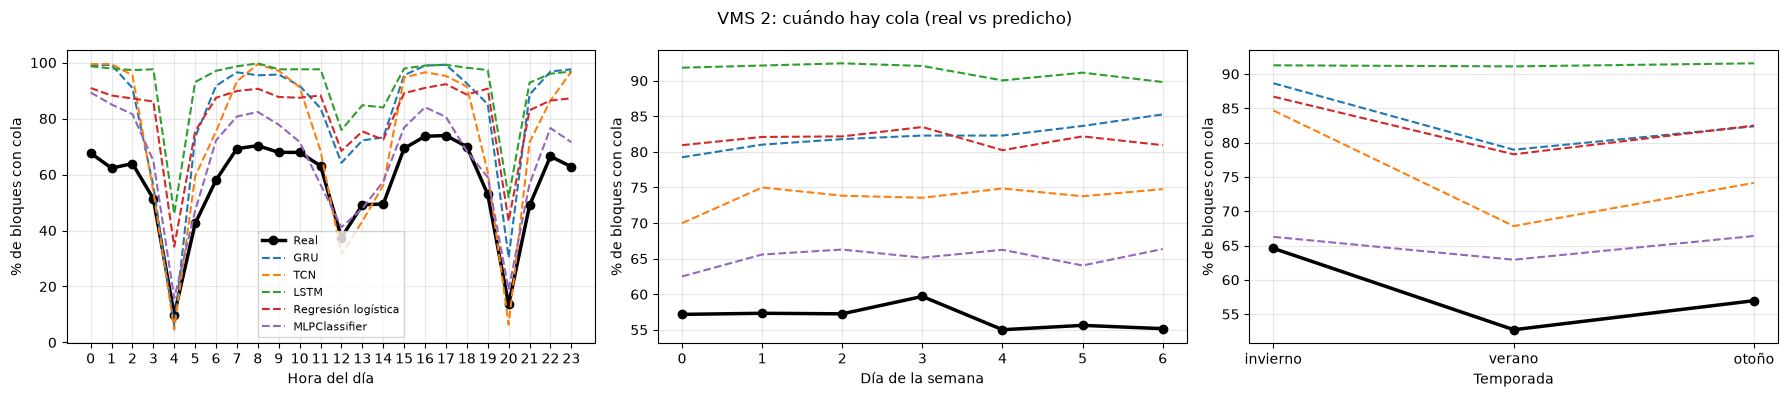

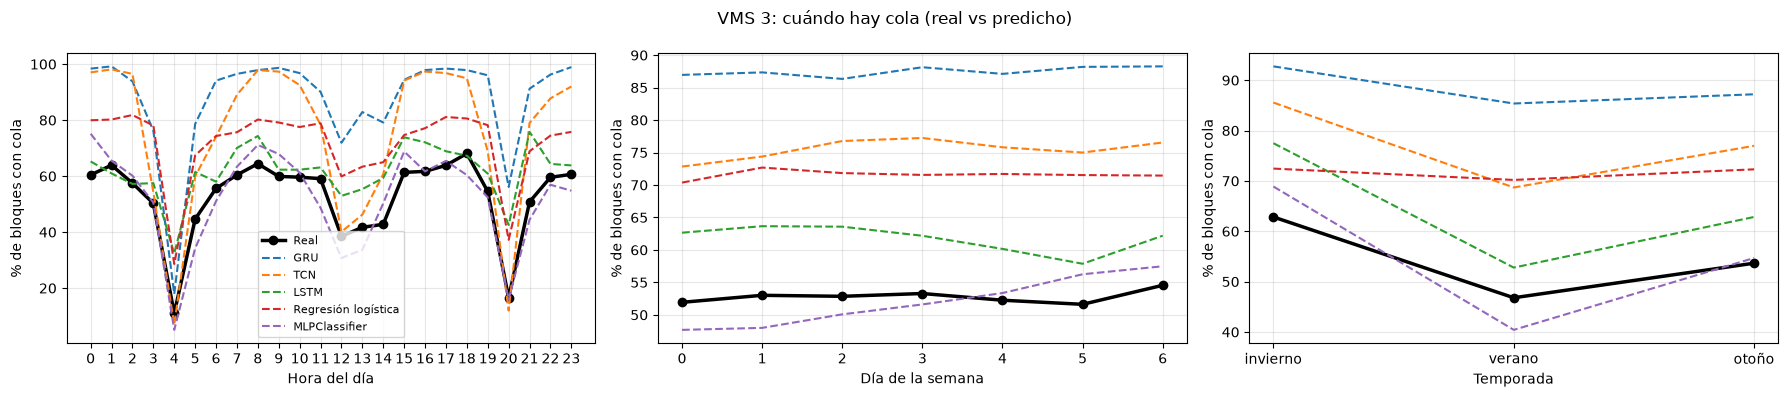

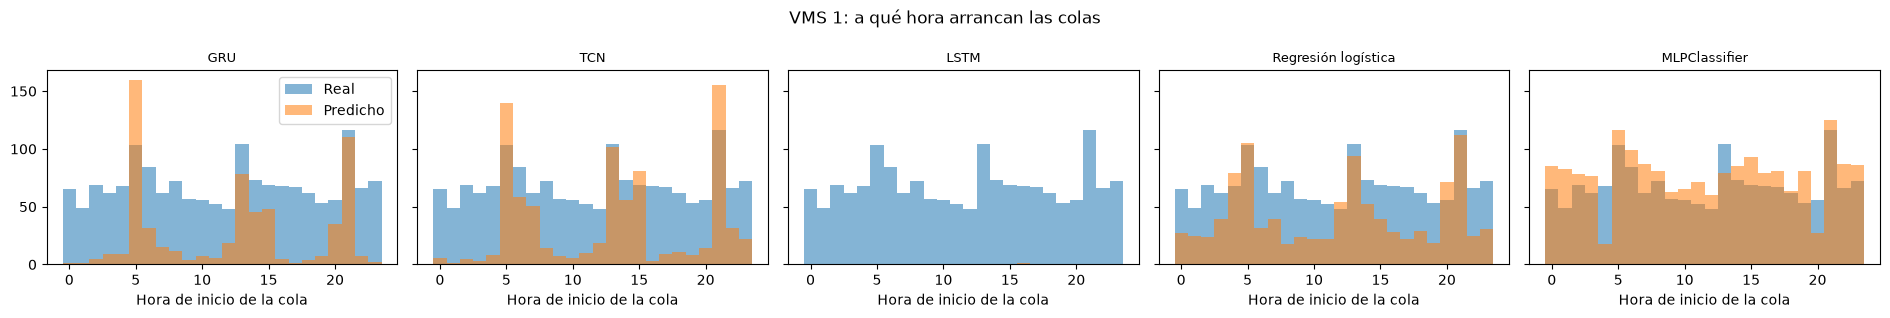

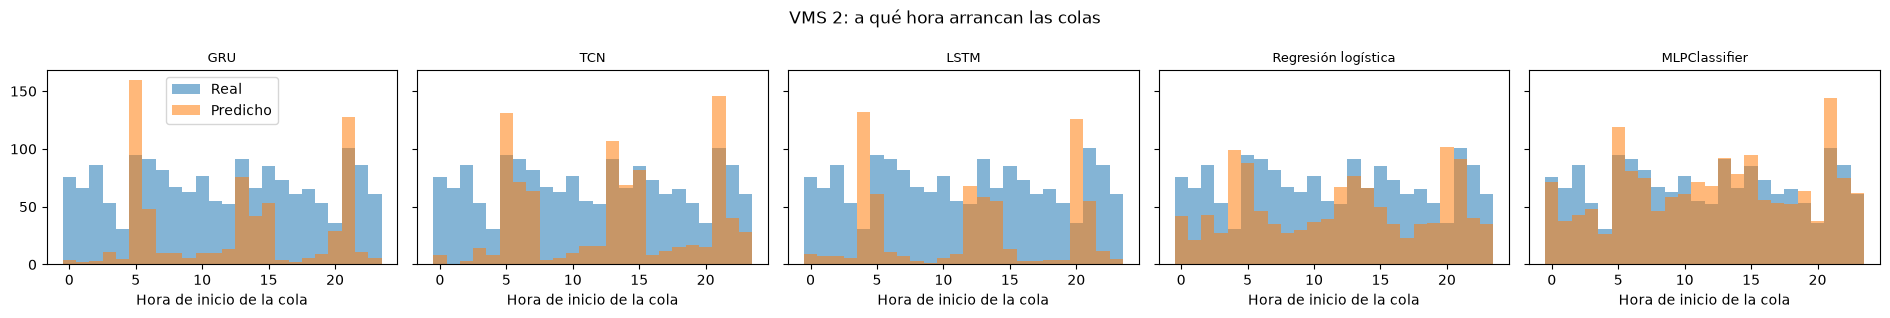

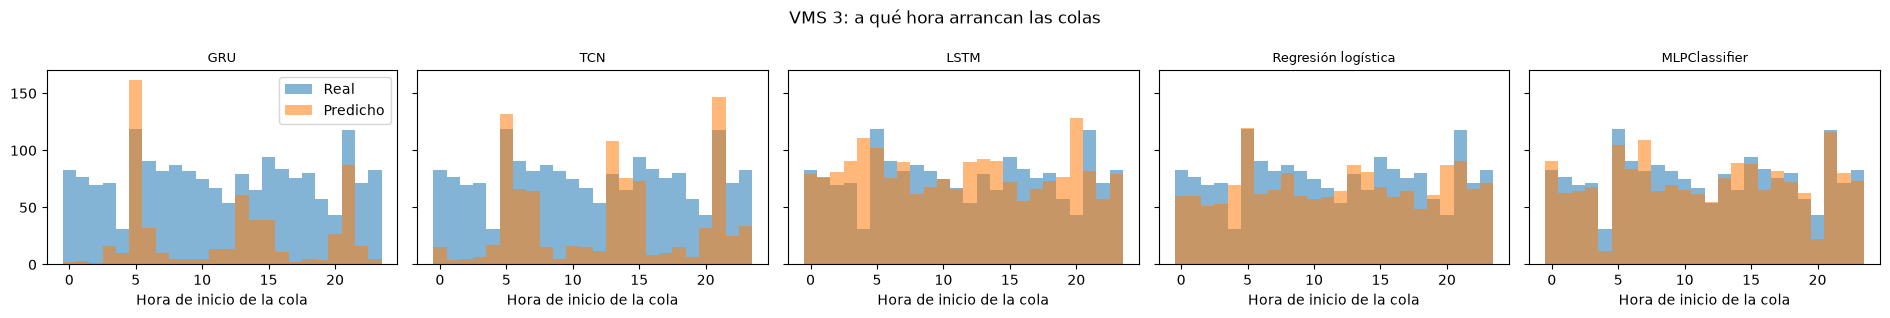

In [6]:
def profile(df, col, value):
    return df.groupby(col)[value].mean().mul(100)


for machine in machines:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, (col, label) in zip(axes, [("hora", "Hora del día"),
                                       ("dia_semana", "Día de la semana"),
                                       ("temporada", "Temporada")]):
        real = profile(base.loc[base["ms"] == machine], col, "y_true")
        if col == "temporada":
            order = [s for s in ["invierno", "primavera", "verano", "otoño"] if s in real.index]
            real = real.reindex(order)
        ax.plot(real.index.astype(str), real.values, "k-o", lw=2.5, label="Real")
        for name in model_names:
            g = frames[name].loc[frames[name]["ms"] == machine]
            pr = profile(g, col, "y_pred").reindex(real.index)
            ax.plot(real.index.astype(str), pr.values, "--", label=name)
        ax.set_xlabel(label)
        ax.set_ylabel("% de bloques con cola")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{machine}: cuándo hay cola (real vs predicho)")
    fig.tight_layout()
    plt.show()

# Hora de inicio de los episodios (real vs predicho)
for machine in machines:
    fig, axes = plt.subplots(1, len(model_names), figsize=(3.8 * len(model_names), 3.2),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes[0], model_names):
        real_df, pred_df, _, _ = episode_store[(machine, name)]
        rh = pd.to_datetime(real_df["inicio"]).dt.hour if len(real_df) else pd.Series(dtype=int)
        ph = pd.to_datetime(pred_df["inicio"]).dt.hour if len(pred_df) else pd.Series(dtype=int)
        bins = np.arange(0, 25) - 0.5
        ax.hist(rh, bins=bins, alpha=0.55, label="Real")
        ax.hist(ph, bins=bins, alpha=0.55, label="Predicho")
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("Hora de inicio de la cola")
    axes[0, 0].legend()
    fig.suptitle(f"{machine}: a qué hora arrancan las colas")
    fig.tight_layout()
    plt.show()